<a href="https://colab.research.google.com/github/DikshyaL/Neplai-Tokenization-Tax/blob/main/nepali_tokenization_tax.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Nepali Tokenization Tax

**How much more does it cost to use AI in Nepali than in English?**

This notebook measures how many tokens the **same 2,009 sentences** cost in English, Nepali, Hindi and nine other languages, across **11 modern tokenizers**. It asks one central question: Nepali and Hindi share the Devanagari script, so is Nepali's extra cost caused by the **script**, or by **how little Nepali data** exists online?

**How to run:** Runtime → Run all. No Hugging Face login is needed. The measuring step takes a few minutes. At the end, the results table and all charts are downloaded as one zip file.

## 0. Install

In [1]:
!pip install -q -U tiktoken transformers sentencepiece

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 72.0 MB/s eta 0:00:00


## 1. Settings

The Devanagari group is the core of the experiment: six languages with the **same script** but very different amounts of online text. Other scripts are included for context.

In [2]:
import os, tarfile, urllib.request, time, logging, warnings, shutil, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tiktoken
import transformers
from transformers import AutoTokenizer
from IPython.display import HTML, display
from html import escape

# Keep the output clean: show real errors only, not chatty warnings
warnings.filterwarnings("ignore")
transformers.logging.set_verbosity_error()
logging.getLogger("transformers_modules").setLevel(logging.ERROR)
logging.getLogger("huggingface_hub").setLevel(logging.ERROR)
try:
    from huggingface_hub.utils import logging as hf_logging
    hf_logging.set_verbosity_error()
except Exception:
    pass

LANGS = {
    "eng_Latn": "English",
    # Devanagari family: same script, very different data sizes
    "hin_Deva": "Hindi",
    "mar_Deva": "Marathi",
    "npi_Deva": "Nepali",
    "mai_Deva": "Maithili",
    "bho_Deva": "Bhojpuri",
    "san_Deva": "Sanskrit",
    # Other scripts, for context
    "ben_Beng": "Bengali",
    "tam_Taml": "Tamil",
    "urd_Arab": "Urdu",
    "zho_Hans": "Chinese",
    "spa_Latn": "Spanish",
}
DEVANAGARI = ["Hindi", "Marathi", "Nepali", "Maithili", "Bhojpuri", "Sanskrit"]
BASELINE = "eng_Latn"

TOKENIZERS = {
    "GPT-4 (cl100k)":    "tiktoken:cl100k_base",
    "GPT-4o (o200k)":    "tiktoken:o200k_base",
    "Llama 3.2":         "unsloth/Llama-3.2-1B",
    "Llama 4":           "unsloth/Llama-4-Scout-17B-16E-Instruct",
    "Qwen3":             "Qwen/Qwen3-0.6B",
    "DeepSeek-V3":       "deepseek-ai/DeepSeek-V3",
    "Mistral Nemo":      "mistralai/Mistral-Nemo-Base-2407",
    "Mistral Small 3.1": "unsloth/Mistral-Small-3.1-24B-Instruct-2503",
    "Gemma 3":           "unsloth/gemma-3-1b-it",
    "Kimi K2":           "moonshotai/Kimi-K2-Instruct",
    "GLM-4.5":           "zai-org/GLM-4.5",
}

IMG_DIR = "images"
os.makedirs(IMG_DIR, exist_ok=True)

## 2. Load FLORES-200

FLORES-200 is a professionally translated benchmark from Meta: the same sentences in 200 languages. We use the `dev` and `devtest` splits together (2,009 sentences per language). If Meta's download link ever fails, the cell falls back to the `flores_plus` copy on Hugging Face (which needs a login).

In [3]:
URL = "https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz"
ROOT = "flores200_dataset"

def load_from_archive():
    if not os.path.exists(ROOT):
        print("Downloading FLORES-200...")
        urllib.request.urlretrieve(URL, "flores200.tar.gz")
        with tarfile.open("flores200.tar.gz") as t:
            try:
                t.extractall(".", filter="data")
            except TypeError:          # older Python without the filter option
                t.extractall(".")
    data = {}
    for code in LANGS:
        sents = []
        for split in ["dev", "devtest"]:
            with open(f"{ROOT}/{split}/{code}.{split}", encoding="utf-8") as f:
                sents += [line.rstrip("\n") for line in f]
        data[code] = sents
    return data

def load_from_hf():
    from datasets import load_dataset
    data = {}
    for code in LANGS:
        sents = []
        for split in ["dev", "devtest"]:
            sents += list(load_dataset("openlanguagedata/flores_plus", code, split=split)["text"])
        data[code] = sents
    return data

try:
    data = load_from_archive()
except Exception as e:
    print("Archive failed, trying flores_plus:", e)
    data = load_from_hf()

n = len(data[BASELINE])
assert all(len(v) == n for v in data.values()), "languages are not aligned"
print(f"{n} parallel sentences x {len(data)} languages")
print("English:", data["eng_Latn"][0])
print("Nepali: ", data["npi_Deva"][0])

2009 parallel sentences x 12 languages
English: On Monday, scientists from the Stanford University School of Medicine announced the invention of a new diagnostic tool that can sort cells by type: a tiny printable chip that can be manufactured using standard inkjet printers for possibly about one U.S. cent each.
Nepali:  सोमबारका दिन, स्ट्यानफोर्ड युनिभर्सिटी स्कुल अफ मेडिसिनका वैज्ञानिकहरूले एक नयाँ डायग्नोस्टिक उपकरणको आविष्कारको घोषणा गरे जसले कोषहरूलाई प्रकारका आधारमा क्रमबद्ध गर्न सक्दछः एउटा सानो प्रिन्ट गर्न सकिने चिप जुन मानक ईंकजेट प्रिन्टरहरू प्रयोग गरेर सम्भवतः लगभग एक अमेरिकी सेन्टको लागतमा निर्माण गर्न सकिन्छ।


## 3. Load tokenizers

Only the small tokenizer files are downloaded, not the models. Any tokenizer that fails to load is skipped and the rest of the notebook continues without it.

In [4]:
def load_tokenizer(spec):
    if spec.startswith("tiktoken:"):
        enc = tiktoken.get_encoding(spec.split(":", 1)[1])
        return {"encode": enc.encode,
                "batch":  lambda texts: [len(x) for x in enc.encode_batch(texts)],
                "decode": lambda i: enc.decode([i]),
                "vocab":  enc.n_vocab}
    kwargs = {"trust_remote_code": True}          # needed for Kimi K2
    if "Mistral-Small" in spec:
        kwargs["fix_mistral_regex"] = True        # fixes a known pre-tokenization bug
    tok = AutoTokenizer.from_pretrained(spec, **kwargs)
    return {"encode": lambda t: tok.encode(t, add_special_tokens=False),
            "batch":  lambda texts: [len(x) for x in tok(texts, add_special_tokens=False)["input_ids"]],
            "decode": lambda i: tok.decode([i]),
            "vocab":  len(tok)}

tokenizers = {}
for name, spec in TOKENIZERS.items():
    try:
        tokenizers[name] = load_tokenizer(spec)
        print(f"Loaded  {name:18s} vocab = {tokenizers[name]['vocab']:,}")
    except Exception as e:
        print(f"Skipped {name:18s} -> {type(e).__name__}: {str(e)[:80]}")

Loaded  GPT-4 (cl100k)     vocab = 100,277
Loaded  GPT-4o (o200k)     vocab = 200,019


config.json:   0%|          | 0.00/889 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.6k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

...

tokenizer_config.json:   0%|          | 0.00/7.31k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 20.0MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/3.24k [00:00<?, ?B/s]

Loaded  GLM-4.5            vocab = 151,365


## 4. Measure

For every tokenizer and language:

- **parity**: tokens for the language ÷ tokens for English on the same sentences (1.00 = same cost as English)
- **tokens per word**, **characters per token**, **bytes per token**: how much text each token carries
- **per-sentence parity**: kept for the distribution plot

Sentences are encoded in batches, so this takes a few minutes rather than much longer.

In [5]:
rows = []
per_sentence = {}

for tk, T in tokenizers.items():
    start = time.time()
    base = np.array(T["batch"](data[BASELINE]))
    for code, sents in data.items():
        lang = LANGS[code]
        counts = np.array(T["batch"](sents))
        per_sentence[(tk, lang)] = counts / np.maximum(base, 1)
        rows.append({
            "tokenizer": tk,
            "vocab": T["vocab"],
            "language": lang,
            "tokens": int(counts.sum()),
            "parity": round(counts.sum() / base.sum(), 2),
            "tokens_per_word": round(counts.sum() / sum(len(s.split()) for s in sents), 2),
            "chars_per_token": round(sum(len(s) for s in sents) / counts.sum(), 2),
            "bytes_per_token": round(sum(len(s.encode("utf-8")) for s in sents) / counts.sum(), 2),
        })
    print(f"done: {tk:18s} ({time.time() - start:.0f}s)")

df = pd.DataFrame(rows)
df.to_csv("token_tax_results.csv", index=False)

tk_order = sorted(tokenizers, key=lambda t: tokenizers[t]["vocab"])
lang_order = df.groupby("language")["parity"].mean().sort_values().index.tolist()
parity = df.pivot(index="tokenizer", columns="language", values="parity").loc[tk_order, lang_order]
print("\nSaved token_tax_results.csv")

done: GPT-4 (cl100k)     (5s)
done: GPT-4o (o200k)     (6s)
done: Llama 3.2          (6s)
done: Llama 4            (4s)
done: Qwen3              (5s)
done: DeepSeek-V3        (6s)
done: Mistral Nemo       (4s)
done: Mistral Small 3.1  (4s)
done: Gemma 3            (4s)
done: Kimi K2            (7s)
done: GLM-4.5            (6s)

Saved token_tax_results.csv


## 5. Results table

Tokenizers sorted from best to worst for Nepali. The last column isolates the Nepali vs Hindi difference: same script, different amounts of data.

In [6]:
summary = pd.DataFrame({
    "vocab": [f"{tokenizers[t]['vocab'] // 1000}k" for t in parity.index],
    "Hindi parity": parity["Hindi"],
    "Nepali parity": parity["Nepali"],
    "Nepali / Hindi": (parity["Nepali"] / parity["Hindi"]).round(2),
}, index=parity.index).sort_values("Nepali parity")
summary

,vocab,Hindi parity,Nepali parity,Nepali / Hindi
tokenizer,,,,
Gemma 3,262k,1.31,1.53,1.17
GPT-4o (o200k),200k,1.58,1.62,1.03
Llama 4,201k,1.65,1.83,1.11
Mistral Nemo,131k,1.80,2.14,1.19
Mistral Small 3.1,131k,1.80,2.14,1.19
Llama 3.2,128k,2.53,2.59,1.02
Kimi K2,163k,2.75,2.80,1.02
DeepSeek-V3,128k,2.81,2.98,1.06
Qwen3,151k,4.43,4.42,1.00


## 6. Visual 1: the full picture

Rows are tokenizers (smallest vocabulary at the top), columns are languages from cheapest to most expensive. Darker = higher tax.

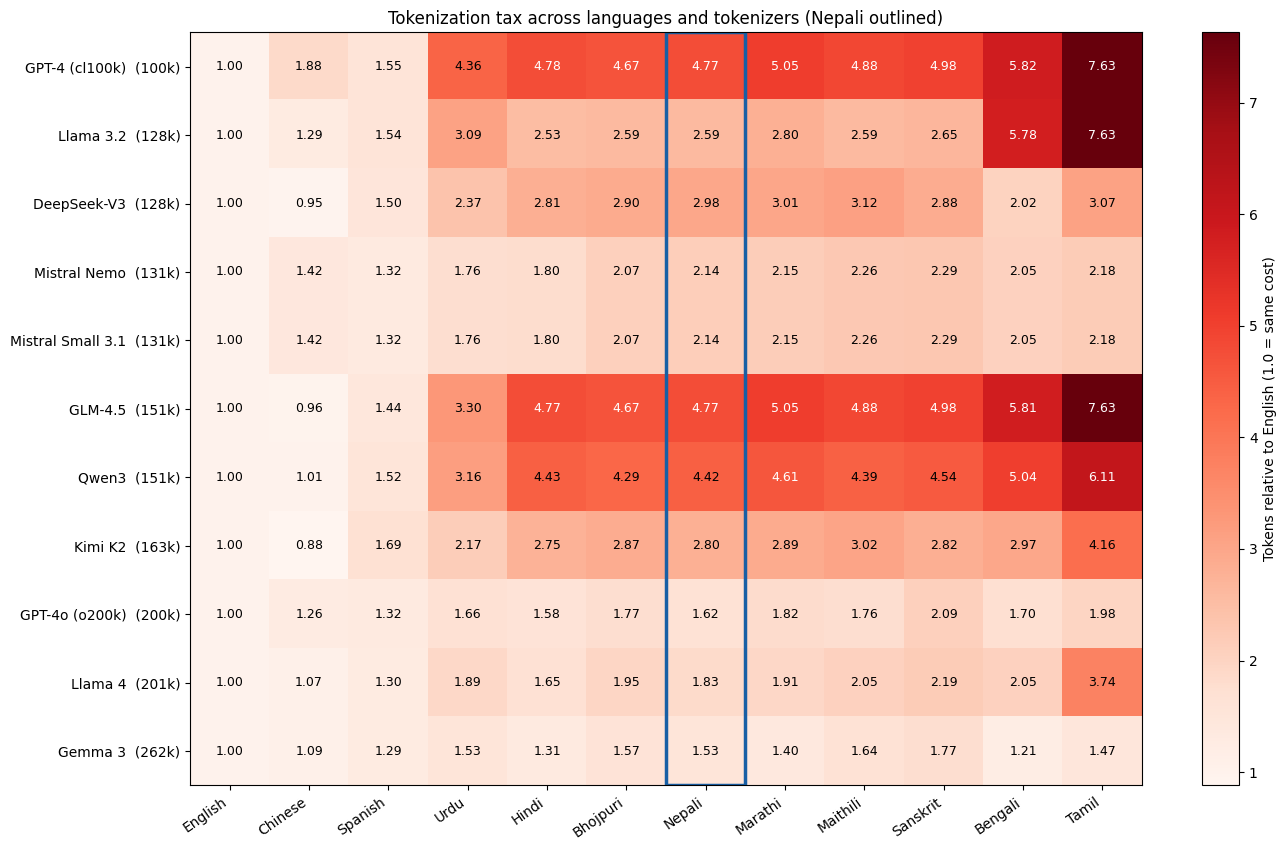

In [7]:
fig, ax = plt.subplots(figsize=(14, 0.6 * len(tk_order) + 2))
im = ax.imshow(parity.values, cmap="Reds", aspect="auto")
ax.set_xticks(range(len(lang_order)), lang_order, rotation=35, ha="right")
ax.set_yticks(range(len(tk_order)),
              [f"{t}  ({tokenizers[t]['vocab']//1000}k)" for t in tk_order])
vmax = parity.values.max()
for i in range(parity.shape[0]):
    for j in range(parity.shape[1]):
        v = parity.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if v > vmax * 0.6 else "black")
for j, lang in enumerate(lang_order):
    if lang == "Nepali":
        ax.add_patch(plt.Rectangle((j - 0.5, -0.5), 1, len(tk_order),
                                   fill=False, lw=2.5, ec="#185FA5"))
plt.colorbar(im, label="Tokens relative to English (1.0 = same cost)")
ax.set_title("Tokenization tax across languages and tokenizers (Nepali outlined)")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Visual 2: English vs Hindi vs Nepali

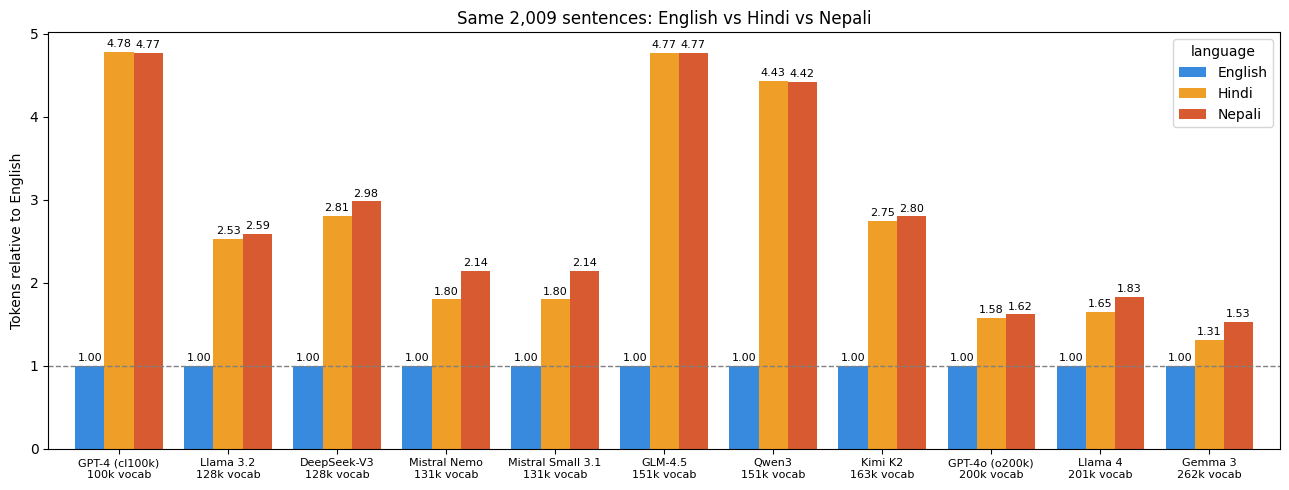

In [8]:
trio = parity[["English", "Hindi", "Nepali"]]
ax = trio.plot.bar(figsize=(13, 5), rot=0, width=0.8,
                   color=["#378ADD", "#EF9F27", "#D85A30"])
ax.axhline(1.0, color="gray", ls="--", lw=1)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticklabels([f"{t}\n{tokenizers[t]['vocab']//1000}k vocab" for t in tk_order], fontsize=8)
ax.set_ylabel("Tokens relative to English")
ax.set_xlabel("")
ax.set_title(f"Same {n:,} sentences: English vs Hindi vs Nepali")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/english_hindi_nepali.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Visual 3: same script, different data

All six languages use Devanagari. If they cost the same, the script drives the tax. If they spread apart, data scarcity does.

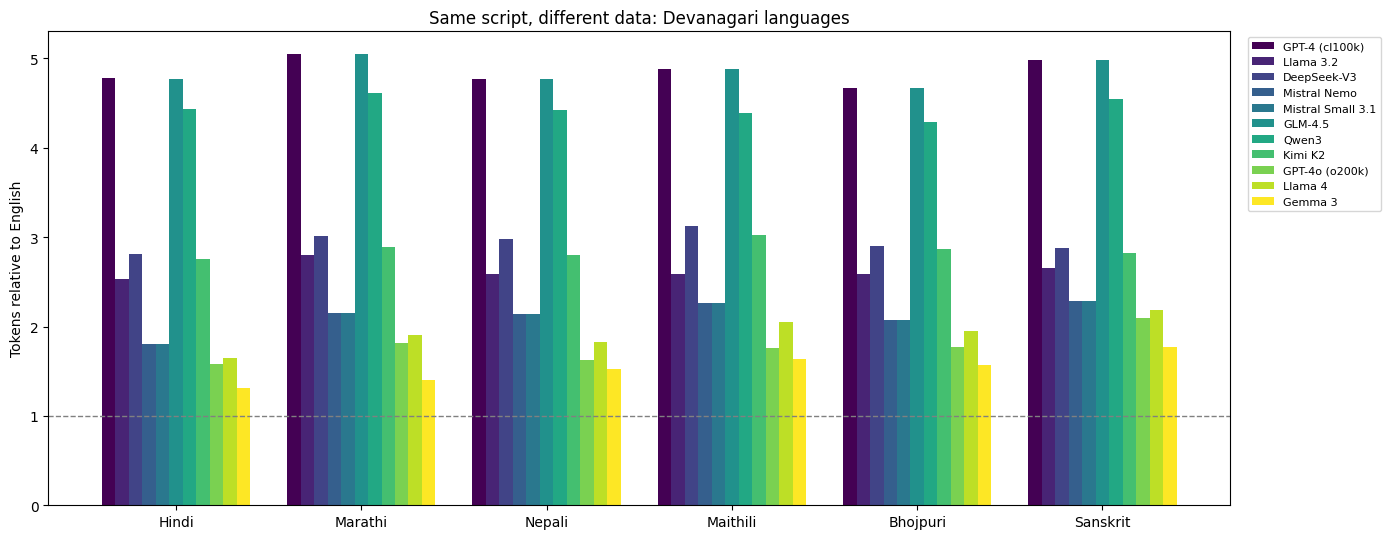

Nepali / Hindi cost ratio (1.00 = Nepali costs the same as Hindi):
tokenizer
GPT-4 (cl100k)       1.00
Llama 3.2            1.02
DeepSeek-V3          1.06
Mistral Nemo         1.19
Mistral Small 3.1    1.19
GLM-4.5              1.00
Qwen3                1.00
Kimi K2              1.02
GPT-4o (o200k)       1.03
Llama 4              1.11
Gemma 3              1.17


In [9]:
deva = parity[DEVANAGARI]
fig, ax = plt.subplots(figsize=(14, 5.5))
x = np.arange(len(DEVANAGARI))
w = 0.8 / len(tk_order)
cmap = plt.get_cmap("viridis", len(tk_order))
for k, tk in enumerate(tk_order):
    ax.bar(x + k * w - 0.4 + w / 2, deva.loc[tk].values, w, label=tk, color=cmap(k))
ax.set_xticks(x, DEVANAGARI)
ax.axhline(1.0, color="gray", ls="--", lw=1)
ax.set_ylabel("Tokens relative to English")
ax.set_title("Same script, different data: Devanagari languages")
ax.legend(fontsize=8, ncol=1, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/devanagari.png", dpi=150, bbox_inches="tight")
plt.show()

print("Nepali / Hindi cost ratio (1.00 = Nepali costs the same as Hindi):")
print((parity["Nepali"] / parity["Hindi"]).round(2).to_string())

## 9. Visual 4: does a bigger vocabulary fix it?

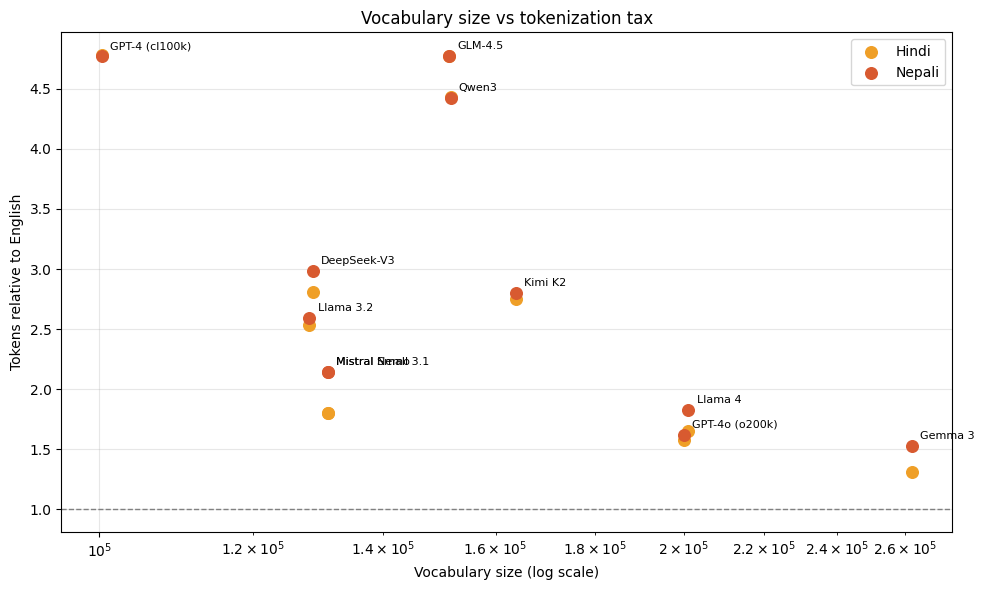

In [10]:
fig, ax = plt.subplots(figsize=(10, 6))
xs = [tokenizers[t]["vocab"] for t in tk_order]
for lang, color in [("Hindi", "#EF9F27"), ("Nepali", "#D85A30")]:
    ys = parity.loc[tk_order, lang].values
    ax.scatter(xs, ys, s=70, color=color, label=lang, zorder=3)
for t, xv, yv in zip(tk_order, xs, parity.loc[tk_order, "Nepali"].values):
    ax.annotate(t, (xv, yv), textcoords="offset points", xytext=(6, 5), fontsize=8)
ax.set_xscale("log")
ax.axhline(1.0, color="gray", ls="--", lw=1)
ax.set_xlabel("Vocabulary size (log scale)")
ax.set_ylabel("Tokens relative to English")
ax.set_title("Vocabulary size vs tokenization tax")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/vocab_vs_tax.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Visual 5: sentence-by-sentence spread for Nepali

An average can hide a lot. Each box shows how the Nepali/English ratio varies across individual sentences.

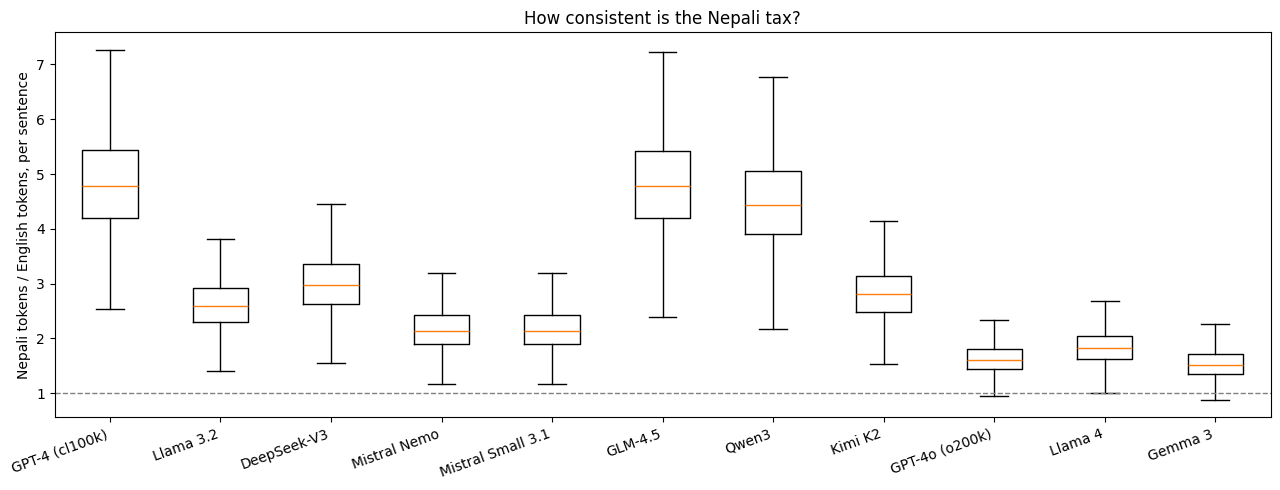

In [11]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.boxplot([per_sentence[(t, "Nepali")] for t in tk_order], showfliers=False)
ax.set_xticks(range(1, len(tk_order) + 1), tk_order, rotation=20, ha="right")
ax.axhline(1.0, color="gray", ls="--", lw=1)
ax.set_ylabel("Nepali tokens / English tokens, per sentence")
ax.set_title("How consistent is the Nepali tax?")
plt.tight_layout()
plt.savefig(f"{IMG_DIR}/nepali_spread.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Visual 6: see the chopping

One sentence in English, Hindi and Nepali, split by each tokenizer. A `�` piece means a Devanagari letter (3 bytes in UTF-8) was split in the middle, so that piece alone cannot be displayed. Change `IDX` to look at other sentences.

In [12]:
IDX = 0
COLORS = ["#FAC775", "#9FE1CB", "#CECBF6", "#F5C4B3"]

def chips(T, text):
    ids = T["encode"](text)
    spans = "".join(
        f'<span style="background:{COLORS[i % 4]};color:#222;padding:2px 5px;margin:2px;'
        f'border-radius:4px;display:inline-block">{escape(T["decode"](t).replace(" ", "␣"))}</span>'
        for i, t in enumerate(ids))
    return len(ids), spans

for tk in tk_order:
    out = f"<h3>{tk}</h3>"
    for code in ["eng_Latn", "hin_Deva", "npi_Deva"]:
        n_tok, html = chips(tokenizers[tk], data[code][IDX])
        out += f"<p><b>{LANGS[code]}</b> ({n_tok} tokens)<br>{html}</p>"
    display(HTML(out))

## 12. Key findings

1. **Nepali pays a tax in every tokenizer.** The same sentences cost between about 1.5× and 4.8× as many tokens in Nepali as in English, depending on the tokenizer.
2. **In weak tokenizers, the script is the bottleneck.** Where Devanagari is split into raw byte fragments (GPT-4 cl100k, GLM-4.5, Qwen3), Nepali and Hindi cost the same (ratio ≈ 1.00).
3. **In strong multilingual tokenizers, data scarcity takes over.** Where real Devanagari subwords were learned (Gemma 3, Mistral, Llama 4), Nepali costs roughly 11–19% more than Hindi despite sharing its script.
4. **Vocabulary size is not destiny.** Similar-sized vocabularies give very different results; what a vocabulary is spent on matters more than its size.

*Note: FLORES-200 is formal news-style text, and these numbers measure cost, not how well models understand Nepali.*

## 13. Download everything

Packs the results table and all charts into one zip file and downloads it. Unzip it and upload the contents to your GitHub repository.

In [13]:
shutil.make_archive("nepali_tokenization_tax_results", "zip", ".", IMG_DIR)
with zipfile.ZipFile("nepali_tokenization_tax_results.zip", "a") as z:
    z.write("token_tax_results.csv")
print("Created nepali_tokenization_tax_results.zip")

try:
    from google.colab import files
    files.download("nepali_tokenization_tax_results.zip")
except ImportError:
    print("Not running in Colab: find the zip file in the current folder.")

Created nepali_tokenization_tax_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>